## 0. Environment check

In [ ]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__)

try:
    import torch; print("torch", torch.__version__)
except ImportError:
    import tensorflow as tf; print("tensorflow", tf.__version__)

# Representative component test: read one raw test 2 snapshot (the P6 data path)
from pathlib import Path
f = sorted(Path("data/ims/2nd_test").iterdir())[0]
x = pd.read_csv(f, sep=r"\s+", header=None).values
print(f.name, x.shape, "RMS per bearing:", np.sqrt((x**2).mean(axis=0)).round(3))

Python 3.12.16 | numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1
torch 2.15.0
2004.02.12.10.32.39 (20480, 4) RMS per bearing: [0.074 0.091 0.109 0.054]


## 1. Held-out test 1: inventory only

In [2]:
## 1. Held-out test 1: inventory only (no signal analysis until predictions are committed)
T1 = Path("data/ims/1st_test")
files1 = sorted(p for p in T1.rglob("*") if p.is_file() and p.name[:4].isdigit())
t1 = pd.to_datetime([p.name for p in files1], format="%Y.%m.%d.%H.%M.%S")
print(len(files1), "files |", t1[0], "→", t1[-1])
print("shape of one file:", pd.read_csv(files1[0], sep=r"\s+", header=None).shape)
gaps1 = pd.Series(t1).diff().dt.total_seconds() / 60
print("interval (min): median", gaps1.median(), "| counts:", gaps1.round().value_counts().head(5).to_dict())

2156 files | 2003-10-22 12:06:24 → 2003-11-25 23:39:56
shape of one file: (20480, 8)
interval (min): median 10.0 | counts: {10.0: 1962, 5.0: 148, 9.0: 5, 6.0: 4, 4.0: 4}


### Decisions fixed before looking at test 1 signals

- **Baseline = every snapshot in the first 24 hours of the run**, chosen by time, not by count. Sampling intervals are not constant (at 5-minute spacing, 144 snapshots would cover only about 12 hours), so a fixed count would cover a different stretch of time in each test.
- **One channel per bearing: the first channel of each pair (columns 0, 2, 4, 6).** This rule is chosen without looking at the data, so it can't be tuned to give a good result. Tests 2 and 3 record one channel per bearing, so using both test 1 channels would give the detector a different kind of input on the held-out test.

## 2. Spectral input (shape only), computed from the raw files

In [3]:
from scipy.signal import welch

FS, N_BANDS = 20_000, 128
EDGES = np.linspace(0, FS / 2, N_BANDS + 1)

def spectrum_shape(x):
    """Welch PSD → 128 linear bands → normalised to total power 1 → log10.
    Removing overall power is the P4 lesson: the detector must not rely on loudness alone."""
    f, p = welch(x - x.mean(), fs=FS, nperseg=2048)
    band = np.bincount(np.digitize(f, EDGES[1:-1]), weights=p, minlength=N_BANDS)
    return np.log10(band / band.sum() + 1e-12).astype("float32")

def build_spectra(name, folder, cols):
    out = Path(f"data/derived/spec_{name}.npz")
    if out.exists():
        d = np.load(out, allow_pickle=True)
        return d["S"], d["rms"], pd.to_datetime(d["time"])
    files = sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.name[:4].isdigit())
    S = np.zeros((len(files), 4, N_BANDS), "float32"); R = np.zeros((len(files), 4), "float32")
    for i, p in enumerate(files):
        x = pd.read_csv(p, sep=r"\s+", header=None).values[:, cols]
        for b in range(4):
            S[i, b] = spectrum_shape(x[:, b]); R[i, b] = np.sqrt((x[:, b] ** 2).mean())
        if i % 500 == 0: print(name, i, "/", len(files))
    t = pd.to_datetime([p.name for p in files], format="%Y.%m.%d.%H.%M.%S")
    np.savez_compressed(out, S=S, rms=R, time=t.astype(str).values)
    return S, R, t

S2, R2, t2 = build_spectra("test2", "data/ims/2nd_test", cols=[0, 1, 2, 3])
S3, R3, t3 = build_spectra("test3", "data/ims/4th_test/txt", cols=[0, 1, 2, 3])
print("test 2:", S2.shape, "| test 3:", S3.shape)

test2 0 / 984
test2 500 / 984
test3 0 / 6324
test3 500 / 6324
test3 1000 / 6324
test3 1500 / 6324
test3 2000 / 6324
test3 2500 / 6324
test3 3000 / 6324
test3 3500 / 6324
test3 4000 / 6324
test3 4500 / 6324
test3 5000 / 6324
test3 5500 / 6324
test3 6000 / 6324
test 2: (984, 4, 128) | test 3: (6324, 4, 128)


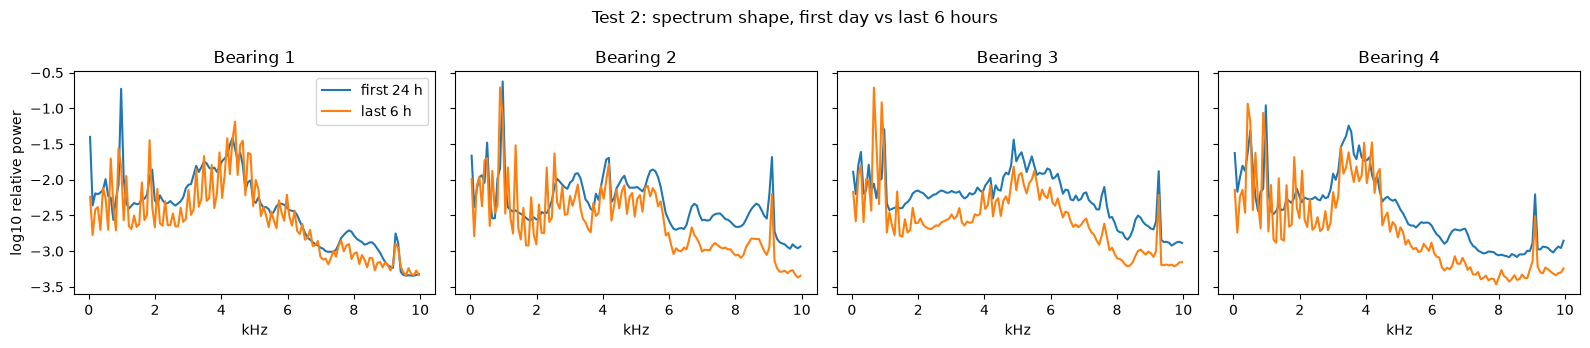

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
freq = (EDGES[:-1] + EDGES[1:]) / 2 / 1000
first_day = t2 < t2[0] + pd.Timedelta(hours=24)
for b, ax in enumerate(axes):
    ax.plot(freq, S2[first_day, b].mean(0), label="first 24 h")
    ax.plot(freq, S2[-36:, b].mean(0), label="last 6 h")
    ax.set_title(f"Bearing {b+1}"); ax.set_xlabel("kHz")
axes[0].set_ylabel("log10 relative power"); axes[0].legend()
plt.suptitle("Test 2: spectrum shape, first day vs last 6 hours"); plt.tight_layout()
plt.savefig("figures/fig1_test2_spectrum_shape.png", dpi=150); plt.show()

## 2b. Check before the VAE: how far does each bearing's shape move from its own first day?

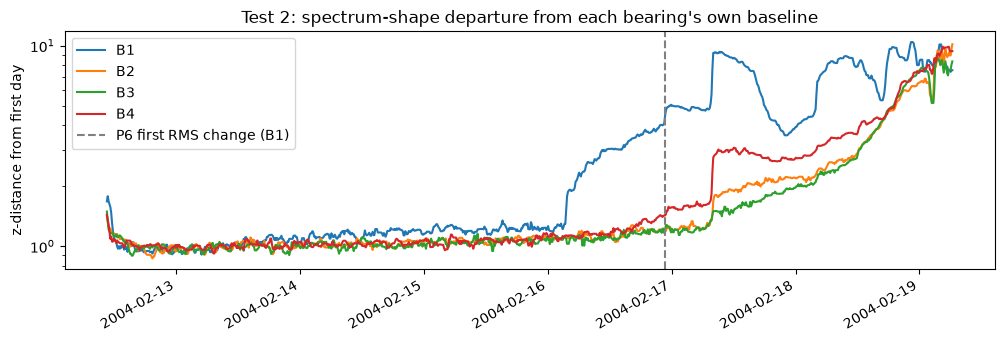

first time above 3:
 B1   2004-02-16 10:32:39
B2   2004-02-18 12:12:39
B3   2004-02-18 12:22:39
B4   2004-02-17 09:02:39
dtype: datetime64[us]


In [5]:
mu_b = S2[first_day].mean(0); sd_b = S2[first_day].std(0) + 1e-6          # per bearing, per band
dist = np.sqrt((((S2 - mu_b) / sd_b) ** 2).mean(axis=2))                  # (snapshots, 4)
d = pd.DataFrame(dist, index=t2, columns=[f"B{b}" for b in range(1, 5)]).rolling(6, min_periods=1).median()

ax = d.plot(figsize=(12, 3.5), logy=True)
ax.axvline(pd.Timestamp("2004-02-16 22:42:39"), ls="--", c="grey", label="P6 first RMS change (B1)")
ax.set_ylabel("z-distance from first day"); ax.legend()
ax.set_title("Test 2: spectrum-shape departure from each bearing's own baseline")
plt.savefig("figures/fig2_test2_shape_departure.png", dpi=150); plt.show()
print("first time above 3:\n", (d > 3).idxmax().where((d > 3).any()))

## 3. Detector: P5's VAE, trained on each run's own first healthy day

In [6]:
import torch, torch.nn as nn

class SpecVAE(nn.Module):
    """1D-convolutional VAE for 128-bin log power spectra."""
    def __init__(self, latent=8):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv1d(1, 16, 5, stride=2, padding=2), nn.LeakyReLU(0.2),   # 128 -> 64
            nn.Conv1d(16, 32, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 64 -> 32
            nn.Conv1d(32, 64, 5, stride=2, padding=2), nn.LeakyReLU(0.2),  # 32 -> 16
            nn.Flatten())
        self.mu, self.logvar = nn.Linear(64 * 16, latent), nn.Linear(64 * 16, latent)
        self.fc = nn.Linear(latent, 64 * 16)
        self.dec = nn.Sequential(
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 16 -> 32
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.LeakyReLU(0.2),  # 32 -> 64
            nn.ConvTranspose1d(16, 1, 4, stride=2, padding=1))                      # 64 -> 128

    def encode(self, x):
        h = self.enc(x); return self.mu(h), self.logvar(h)

    def decode(self, z):
        return self.dec(self.fc(z).view(-1, 64, 16))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)   # reparameterisation trick
        return self.decode(z), mu, logvar

def vae_loss(x, xr, mu, logvar, beta=1.0):
    """Negative ELBO per sample: Gaussian reconstruction (sum of squared errors) + beta * KL."""
    rec = ((x - xr) ** 2).sum(dim=(1, 2)).mean()
    kl = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)).mean()
    return rec + beta * kl, rec, kl

In [8]:
def score(model, x):
    """P5's anomaly score: decode from mu (deterministic), sum of squared errors over 128 bins."""
    model.eval()
    with torch.no_grad():
        h = model.enc(x); mu = model.mu(h)
        rec = model.dec(model.fc(mu).view(-1, 64, 16))
        return ((rec - x) ** 2).sum(dim=(1, 2)).numpy()

def fit_detector(S, t, name, train_h=18, val_h=6, epochs=60, q=0.99):
    out = Path(f"data/derived/detector_{name}.npz")
    tr = t < t[0] + pd.Timedelta(hours=train_h)
    va = (t >= t[0] + pd.Timedelta(hours=train_h)) & (t < t[0] + pd.Timedelta(hours=train_h + val_h))
    if out.exists():
        d = np.load(out); return d["scores"], d["thr"], tr, va
    mean, std = S[tr].reshape(-1, 128).mean(0), S[tr].reshape(-1, 128).std(0) + 1e-6
    Z = ((S - mean) / std).astype("float32")
    torch.manual_seed(0)
    model = SpecVAE(latent=8); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    Xtr = torch.tensor(Z[tr].reshape(-1, 1, 128))
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(Xtr)).split(128):
            xb = Xtr[idx]
            rec, mu, lv = model(xb)
            loss, _, _ = vae_loss(xb, rec, mu, lv)   # vae_loss(x, xr, mu, logvar) returns (total, rec, kl)
            opt.zero_grad(); loss.backward(); opt.step()
    scores = score(model, torch.tensor(Z.reshape(-1, 1, 128))).reshape(len(S), 4)
    thr = np.array([np.quantile(scores[va, b], q) for b in range(4)])
    torch.save(model.state_dict(), f"data/derived/vae_{name}.pt")
    np.savez(out, scores=scores, thr=thr)
    return scores, thr, tr, va

sc2, thr2, tr2, va2 = fit_detector(S2, t2, "test2")
print("train / val snapshots:", tr2.sum(), va2.sum(), "| thresholds per bearing:", thr2.round(1))

train / val snapshots: 108 36 | thresholds per bearing: [22.1 23.1 23.2 24.2]
